# SC5002 Lab Assignment — Part 2: Linear vs Ridge Regression on California Housing

**Author:** YU XIYAO · U2440309D  
**Course:** SC5002 Artificial Intelligence Fundamentals & Applications, NTU

This notebook runs the course-provided template (Cells 1–3, logic unchanged; only copy-paste formatting errors fixed),
followed by optional extension experiments that dig deeper into *why* the results look the way they do.

| Cell | Task | What it does |
|---|---|---|
| 1 | 2.1 | Load data, sample 1,000 rows, scale features, train/test split |
| 2 | 2.2 | 5-fold CV for Linear Regression and Ridge (α = 0.1, 10, 1000) |
| 3 | 2.3 | Bar chart comparing mean CV R² |
| 4–8 | Extension | Fold-level variance, α sweep, coefficient shrinkage, leakage-free pipeline, held-out test score |


## Cell 1 — Task 2.1: Dataset Setup
Loads the California Housing dataset (20,640 districts, 1990 US Census), samples 1,000 rows with a fixed seed,
separates the target `MedHouseVal` (median house value, in units of $100,000) from the 8 input features,
standardises the features and holds out 20% as a test set.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.preprocessing import StandardScaler

# --- TASK 2.1: DATASET SETUP ---
print("=== TASK 2.1: Loading California Housing Dataset ===")
housing = fetch_california_housing(as_frame=True)
df = housing.frame.sample(n=1000, random_state=42)  # Sample 1000 records
print("First 5 rows of dataset (Copy these for AI Prompt 2.1):")
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 20)
print(df.head())

X = df.drop(columns=['MedHouseVal'])
y = df['MedHouseVal']

# Scale numerical features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)
print(f"\nTraining rows: {X_train.shape[0]}, Test rows: {X_test.shape[0]}, Features: {X_train.shape[1]}")

=== TASK 2.1: Loading California Housing Dataset ===
First 5 rows of dataset (Copy these for AI Prompt 2.1):
       MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  Longitude  MedHouseVal
20046  1.6812      25.0  4.192201   1.022284      1392.0  3.877437     36.06    -119.01      0.47700
3024   2.5313      30.0  5.039384   1.193493      1565.0  2.679795     35.14    -119.46      0.45800
15663  3.4801      52.0  3.977155   1.185877      1310.0  1.360332     37.80    -122.44      5.00001
20484  5.7376      17.0  6.163636   1.020202      1705.0  3.444444     34.28    -118.72      2.18600
9814   3.7250      34.0  5.492991   1.028037      1063.0  2.483645     36.62    -121.93      2.78000

Training rows: 800, Test rows: 200, Features: 8


## Cell 2 — Task 2.2: Model Training & 5-Fold Cross-Validation
Each model is trained 5 times on 4/5 of the training data and scored (R²) on the remaining 1/5.
The reported number is the mean of the 5 scores.

In [2]:
# --- TASK 2.2: MODEL TRAINING & CROSS-VALIDATION ---
print("=== TASK 2.2: Training Linear Regression ===")
lin_reg = LinearRegression()
lin_scores = cross_val_score(lin_reg, X_train, y_train, cv=5, scoring='r2')
print(f"Linear Regression Mean 5-Fold R2 Score: {lin_scores.mean():.4f}")

# Ridge Regression Experiments
alphas = [0.1, 10.0, 1000.0]
ridge_results = {}
ridge_fold_scores = {}  # (added) keep per-fold scores for the extension cells

print("--- Training Ridge Regression with Varying Alpha Values ---")
for a in alphas:
    ridge = Ridge(alpha=a)
    scores = cross_val_score(ridge, X_train, y_train, cv=5, scoring='r2')
    ridge_results[a] = scores.mean()
    ridge_fold_scores[a] = scores
    print(f"Ridge Regression (alpha={a:6.1f}) Mean 5-Fold R2 Score: {scores.mean():.4f}")

=== TASK 2.2: Training Linear Regression ===
Linear Regression Mean 5-Fold R2 Score: 0.6457
--- Training Ridge Regression with Varying Alpha Values ---
Ridge Regression (alpha=   0.1) Mean 5-Fold R2 Score: 0.6457
Ridge Regression (alpha=  10.0) Mean 5-Fold R2 Score: 0.6443
Ridge Regression (alpha=1000.0) Mean 5-Fold R2 Score: 0.3574


## Cell 3 — Task 2.3: Model Comparison Chart

=== TASK 2.3: Generating Model Comparison Chart ===


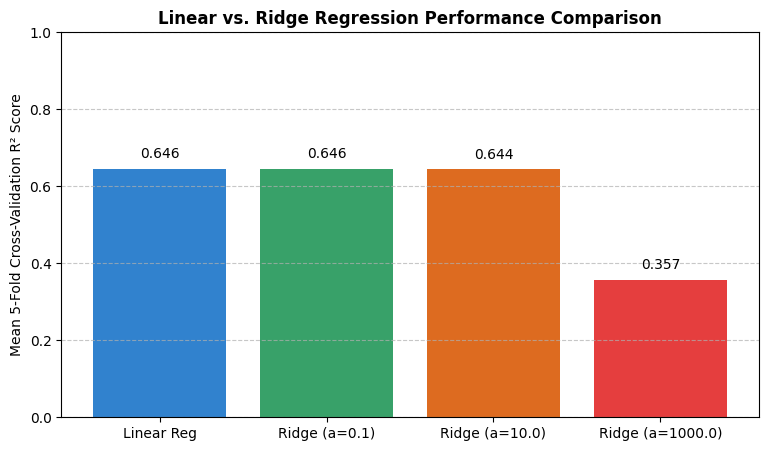

In [3]:
# --- TASK 2.3: VISUALIZATION ---
print("=== TASK 2.3: Generating Model Comparison Chart ===")
plt.figure(figsize=(9, 5))
models = ['Linear Reg'] + [f'Ridge (a={a})' for a in alphas]
scores = [lin_scores.mean()] + list(ridge_results.values())
bars = plt.bar(models, scores, color=['#3182ce', '#38a169', '#dd6b20', '#e53e3e'])
plt.ylabel('Mean 5-Fold Cross-Validation R² Score', fontsize=10)
plt.title('Linear vs. Ridge Regression Performance Comparison', fontsize=12, fontweight='bold')
plt.ylim(0, 1.0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 0.02, f'{yval:.3f}', ha='center', va='bottom')
plt.savefig('model_comparison.png', dpi=200, bbox_inches='tight')  # (added) save for report / README
plt.show()

---
# Extension Experiments (beyond the template)
The template answers *what* the scores are. The cells below answer *why*.

## Cell 4 — How much does a single split's score vary?
If a single train/test split were reliable, the 5 fold scores would be nearly identical.

In [4]:
fold_table = pd.DataFrame({'Linear Reg': lin_scores,
                           **{f'Ridge a={a}': ridge_fold_scores[a] for a in alphas}},
                          index=[f'Fold {i+1}' for i in range(5)])
summary = pd.DataFrame({'Mean': fold_table.mean(), 'Std': fold_table.std(),
                        'Min': fold_table.min(), 'Max': fold_table.max()}).T
print("Per-fold R² scores:")
print(pd.concat([fold_table, summary]).round(4).to_string())
spread = lin_scores.max() - lin_scores.min()
print(f"\nLinear Regression: a single split could have reported anything from "
      f"{lin_scores.min():.3f} to {lin_scores.max():.3f} (a spread of {spread:.3f}).")

Per-fold R² scores:
        Linear Reg  Ridge a=0.1  Ridge a=10.0  Ridge a=1000.0
Fold 1      0.7494       0.7494        0.7442          0.4043
Fold 2      0.6018       0.6019        0.6032          0.3384
Fold 3      0.6308       0.6310        0.6419          0.3775
Fold 4      0.6385       0.6385        0.6334          0.3686
Fold 5      0.6080       0.6079        0.5989          0.2983
Mean        0.6457       0.6457        0.6443          0.3574
Std         0.0600       0.0599        0.0588          0.0405
Min         0.6018       0.6019        0.5989          0.2983
Max         0.7494       0.7494        0.7442          0.4043

Linear Regression: a single split could have reported anything from 0.602 to 0.749 (a spread of 0.148).


## Cell 5 — Sweeping α continuously
Instead of three α values, test 50 values from 0.001 to 10,000 to see the whole curve.

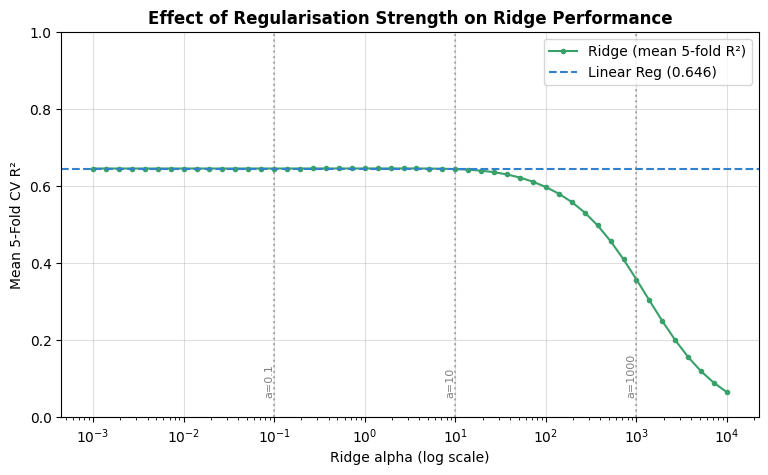

Best alpha in sweep: 1.931  (mean R² = 0.6459)


In [5]:
alpha_grid = np.logspace(-3, 4, 50)
sweep = [cross_val_score(Ridge(alpha=a), X_train, y_train, cv=5, scoring='r2').mean() for a in alpha_grid]
best_alpha = alpha_grid[int(np.argmax(sweep))]

plt.figure(figsize=(9, 5))
plt.semilogx(alpha_grid, sweep, marker='.', color='#38a169', label='Ridge (mean 5-fold R²)')
plt.axhline(lin_scores.mean(), color='#3182ce', linestyle='--', label=f'Linear Reg ({lin_scores.mean():.3f})')
for a in alphas:
    plt.axvline(a, color='grey', linestyle=':', alpha=0.6)
    plt.text(a, 0.05, f'a={a:g}', rotation=90, va='bottom', ha='right', fontsize=8, color='grey')
plt.xlabel('Ridge alpha (log scale)')
plt.ylabel('Mean 5-Fold CV R²')
plt.title('Effect of Regularisation Strength on Ridge Performance', fontweight='bold')
plt.ylim(0, 1.0)
plt.grid(alpha=0.4)
plt.legend()
plt.savefig('alpha_sweep.png', dpi=200, bbox_inches='tight')
plt.show()
print(f"Best alpha in sweep: {best_alpha:.4g}  (mean R² = {max(sweep):.4f})")

## Cell 6 — What does a large α actually do to the model?
Ridge adds a penalty on the size of the coefficients. Larger α → smaller coefficients → a simpler model.

Model coefficients (features are standardised, so sizes are comparable):
            Linear Reg  Ridge a=0.1  Ridge a=10  Ridge a=1000
MedInc           0.801        0.801       0.800         0.333
HouseAge         0.137        0.137       0.147         0.064
AveRooms        -0.120       -0.120      -0.113         0.083
AveBedrms        0.210        0.210       0.191        -0.018
Population       0.053        0.053       0.056         0.007
AveOccup        -0.260       -0.260      -0.262        -0.124
Latitude        -0.905       -0.903      -0.776        -0.089
Longitude       -0.842       -0.840      -0.713        -0.054

Sum of |coefficients|:
Linear Reg      3.328
Ridge a=0.1     3.325
Ridge a=10      3.058
Ridge a=1000    0.770


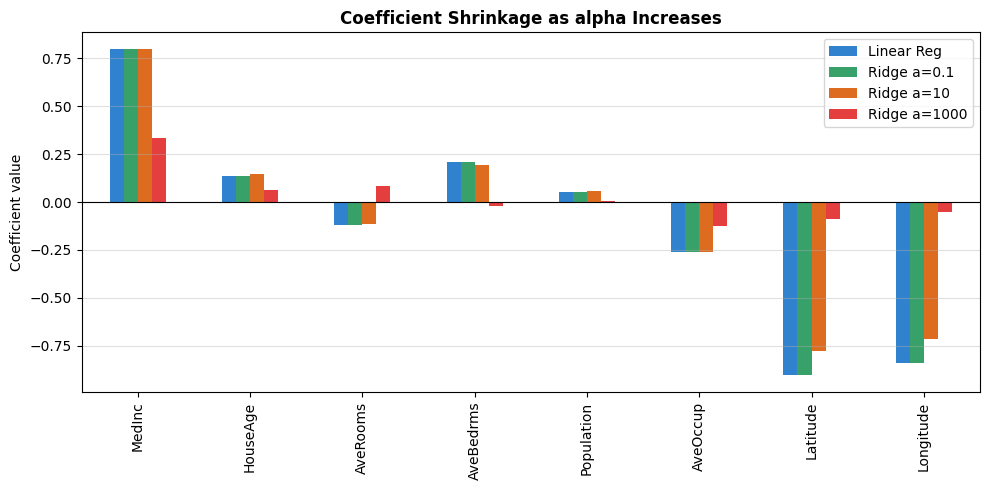

In [6]:
feature_names = X.columns
coef_table = pd.DataFrame({'Linear Reg': LinearRegression().fit(X_train, y_train).coef_},
                          index=feature_names)
for a in alphas:
    coef_table[f'Ridge a={a:g}'] = Ridge(alpha=a).fit(X_train, y_train).coef_
print("Model coefficients (features are standardised, so sizes are comparable):")
print(coef_table.round(3).to_string())
print("\nSum of |coefficients|:")
print(coef_table.abs().sum().round(3).to_string())

coef_table.plot(kind='bar', figsize=(10, 5), color=['#3182ce', '#38a169', '#dd6b20', '#e53e3e'])
plt.axhline(0, color='black', linewidth=0.8)
plt.ylabel('Coefficient value')
plt.title('Coefficient Shrinkage as alpha Increases', fontweight='bold')
plt.grid(axis='y', alpha=0.4)
plt.tight_layout()
plt.savefig('coefficient_shrinkage.png', dpi=200, bbox_inches='tight')
plt.show()

## Cell 7 — Data-leakage check
The template fits `StandardScaler` on **all** 1,000 rows before splitting, so the test rows influence the scaling.
The correct approach fits the scaler only on training data, inside each CV fold, using a `Pipeline`.

In [7]:
from sklearn.pipeline import make_pipeline

X_raw_train, X_raw_test, y_raw_train, y_raw_test = train_test_split(X, y, test_size=0.2, random_state=42)
rows = []
for name, model in [('Linear Reg', LinearRegression())] + [(f'Ridge a={a:g}', Ridge(alpha=a)) for a in alphas]:
    leaky = cross_val_score(model, X_train, y_train, cv=5, scoring='r2').mean()
    clean = cross_val_score(make_pipeline(StandardScaler(), model), X_raw_train, y_raw_train, cv=5, scoring='r2').mean()
    rows.append([name, leaky, clean, clean - leaky])
print(pd.DataFrame(rows, columns=['Model', 'Template (scaled before split)', 'Pipeline (no leakage)', 'Difference'])
        .round(4).to_string(index=False))

       Model  Template (scaled before split)  Pipeline (no leakage)  Difference
  Linear Reg                          0.6457                 0.6457      0.0000
 Ridge a=0.1                          0.6457                 0.6457     -0.0000
  Ridge a=10                          0.6443                 0.6443      0.0000
Ridge a=1000                          0.3574                 0.3606      0.0032


## Cell 8 — Final check on the untouched test set
Cross-validation used only the training data. The 200 test rows have never been used — this is the final, honest score.

In [8]:
from sklearn.metrics import r2_score, mean_absolute_error
rows = []
for name, model in [('Linear Reg', LinearRegression()), ('Ridge a=10', Ridge(alpha=10.0)), ('Ridge a=1000', Ridge(alpha=1000.0))]:
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    rows.append([name, r2_score(y_test, pred), mean_absolute_error(y_test, pred) * 100000])
print(pd.DataFrame(rows, columns=['Model', 'Test R²', 'Test MAE (USD)']).round(4).to_string(index=False))

       Model  Test R²  Test MAE (USD)
  Linear Reg   0.6619      50399.0503
  Ridge a=10   0.6575      50473.4784
Ridge a=1000   0.4009      74556.9880
